In [60]:
#PROJECT 1 — Student Performance Prediction System
!pip install numpy pandas matplotlib seaborn scikit-learn joblib


In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [62]:
df = pd.read_csv("Project_1_Student_Performance.csv")

print(df.head())


  Student_ID  Attendance  Internal_Marks  Assignments  Study_Hours  \
0     STU001          59              87           62          7.5   
1     STU002          90              52           90          1.2   
2     STU003          85              90           40          4.9   
3     STU004          75              52           94          5.4   
4     STU005          74              61           73          1.7   

   Previous_Sem_Result  Final_Marks  
0                 52.5         73.3  
1                 92.7         77.5  
2                 67.3         98.4  
3                 64.5         79.5  
4                 82.2         73.4  


In [63]:
print("Shape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Shape of dataset:
(150, 7)

Column names:
Index(['Student_ID', 'Attendance', 'Internal_Marks', 'Assignments',
       'Study_Hours', 'Previous_Sem_Result', 'Final_Marks'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           150 non-null    object 
 1   Attendance           150 non-null    int64  
 2   Internal_Marks       150 non-null    int64  
 3   Assignments          150 non-null    int64  
 4   Study_Hours          150 non-null    float64
 5   Previous_Sem_Result  150 non-null    float64
 6   Final_Marks          150 non-null    float64
dtypes: float64(3), int64(3), object(1)
memory usage: 8.3+ KB


In [64]:
print(df.isnull().sum())

Student_ID             0
Attendance             0
Internal_Marks         0
Assignments            0
Study_Hours            0
Previous_Sem_Result    0
Final_Marks            0
dtype: int64


In [65]:
df = df.drop_duplicates()

df = df.fillna(df.median(numeric_only=True))

print(df.isnull().sum())

Student_ID             0
Attendance             0
Internal_Marks         0
Assignments            0
Study_Hours            0
Previous_Sem_Result    0
Final_Marks            0
dtype: int64


In [66]:
df.describe()

,Attendance,Internal_Marks,Assignments,Study_Hours,Previous_Sem_Result,Final_Marks
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,78.226667,63.986667,69.373333,4.446667,70.500667,79.491333
std,12.684688,16.446777,18.935265,2.015333,15.039909,9.956799
min,55.000000,36.000000,40.000000,1.100000,45.300000,48.100000
25%,67.250000,51.000000,53.250000,2.700000,56.675000,72.300000
50%,79.500000,63.000000,68.000000,4.550000,71.000000,79.550000
75%,90.000000,77.000000,86.000000,6.375000,82.975000,84.700000
max,100.000000,95.000000,100.000000,7.900000,96.000000,100.000000


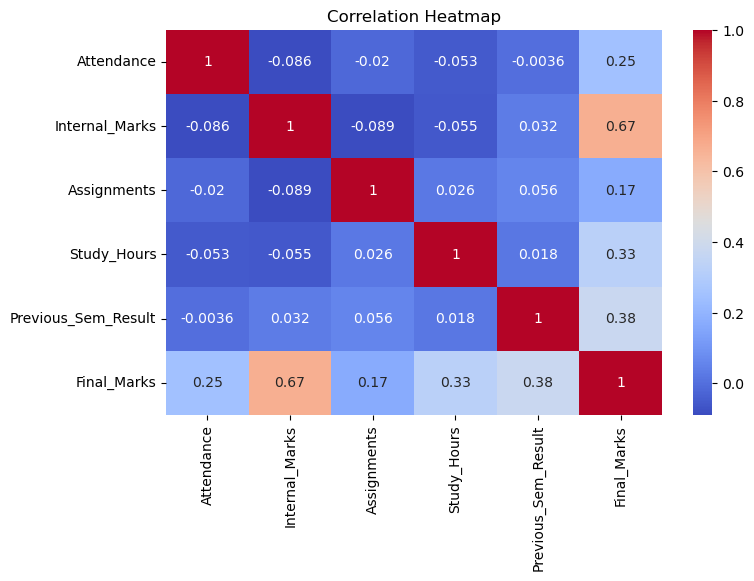

In [67]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

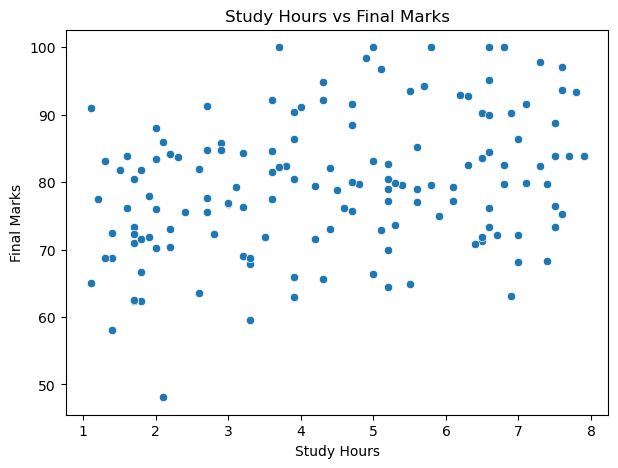

In [68]:
#Study Hours vs Final Marks
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Marks"
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")

plt.show()

In [69]:
X = df[
    [
        "Attendance",
        "Internal_Marks",
        "Assignments",
        "Study_Hours",
        "Previous_Sem_Result"
    ]
]

y = df["Final_Marks"]

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 5)
Testing data: (30, 5)


In [71]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [72]:
#Prediction
linear_prediction = linear_model.predict(X_test)

print(linear_prediction[:10])

[64.86542574 85.47444798 77.97058073 77.72173993 88.17396081 67.79412563
 78.80138836 70.01889903 61.33982229 67.48600923]


In [73]:
mae_linear = mean_absolute_error(
    y_test,
    linear_prediction
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        linear_prediction
    )
)

r2_linear = r2_score(
    y_test,
    linear_prediction
)

print("Linear Regression")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R2  :", r2_linear)

Linear Regression
MAE : 3.092265122176395
RMSE: 4.054699632554065
R2  : 0.8463888109199702


In [74]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

,steps,"[('imputer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,n_estimators,100


In [75]:
#Prediction
rf_prediction = rf_model.predict(X_test)

print(rf_prediction[:10])

[70.722 82.55  81.841 78.696 88.529 71.328 85.037 76.536 69.252 67.601]


In [76]:
#Evaluation
mae_rf = mean_absolute_error(
    y_test,
    rf_prediction
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        rf_prediction
    )
)

r2_rf = r2_score(
    y_test,
    rf_prediction
)

print("Random Forest Regression")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R2  :", r2_rf)

Random Forest Regression
MAE : 4.39173333333333
RMSE: 5.608880672647615
R2  : 0.706060550289563


In [77]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    
    "MAE": [
        mae_linear,
        mae_rf
    ],
    
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    
    "R2": [
        r2_linear,
        r2_rf
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,3.092265,4.054700,0.846389
1,Random Forest,4.391733,5.608881,0.706061


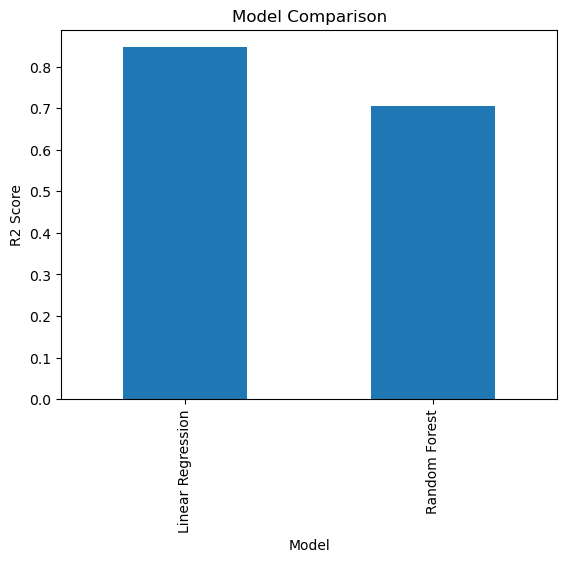

In [78]:
#Graph
comparison.plot(
    x="Model",
    y="R2",
    kind="bar",
    legend=False
)

plt.title("Model Comparison")
plt.ylabel("R2 Score")
plt.show()

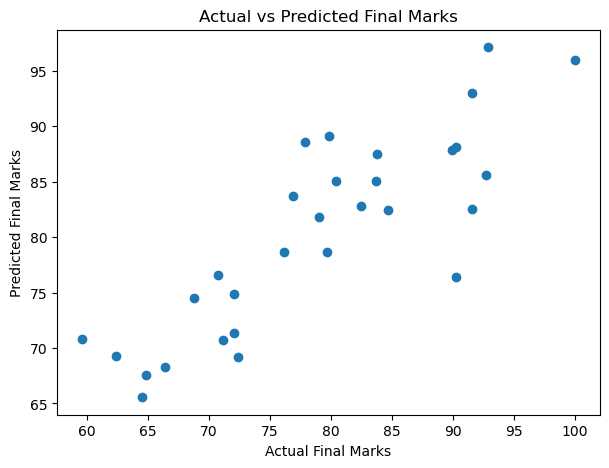

In [79]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_prediction
)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")

plt.title(
    "Actual vs Predicted Final Marks"
)

plt.show()

In [80]:
new_student = pd.DataFrame({
    "Attendance": [90],
    "Internal_Marks": [82],
    "Assignments": [85],
    "Study_Hours": [5],
    "Previous_Sem_Result": [78]
})

In [81]:
#Prediction
prediction = rf_model.predict(new_student)

print(
    "Predicted Final Marks:",
    round(float(prediction[0]), 2)
)


Predicted Final Marks: 95.82


In [82]:
joblib.dump(
    rf_model,
    "student_performance_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
